# 1. Global methane levels from 2002

In [1]:
import glob
import warnings
import netCDF4
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [2]:
# 1.1
# 1.读取数据
ds = xr.open_dataset("./Data/200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")

print("=== 数据集基本信息 ===")
print(ds)

xch4_raw = ds["xch4"]

print("\n=== 变量单位 ===")
print("单位属性：", xch4_raw.attrs.get("units", "未标注"))

print("\n=== 数值分布探查 ===")
print("最小值：%.4e" % float(xch4_raw.min(skipna=True)))
print("最大值：%.4e" % float(xch4_raw.max(skipna=True)))
print("中位数：%.4e" % float(xch4_raw.median(skipna=True)))
print("99%%分位数：%.4e" % float(xch4_raw.quantile(0.99, skipna=True)))

=== 数据集基本信息 ===
<xarray.Dataset> Size: 54MB
Dimensions:                  (time: 210, bnds: 2, lat: 36, lon: 72, pressure: 10)
Coordinates:
  * time                     (time) datetime64[ns] 2kB 2003-01-16T12:00:00 .....
  * lat                      (lat) float64 288B -87.5 -82.5 -77.5 ... 82.5 87.5
  * lon                      (lon) float64 576B -177.5 -172.5 ... 172.5 177.5
Dimensions without coordinates: bnds, pressure
Data variables:
    time_bnds                (time, bnds) datetime64[ns] 3kB ...
    lat_bnds                 (lat, bnds) float64 576B ...
    lon_bnds                 (lon, bnds) float64 1kB ...
    pre                      (pressure) float64 80B ...
    pre_bnds                 (pressure, bnds) float64 160B ...
    land_fraction            (lat, lon) float64 21kB ...
    xch4                     (time, lat, lon) float32 2MB ...
    xch4_nobs                (time, lat, lon) float64 4MB ...
    xch4_stderr              (time, lat, lon) float32 2MB ...
    xch4_stddev  

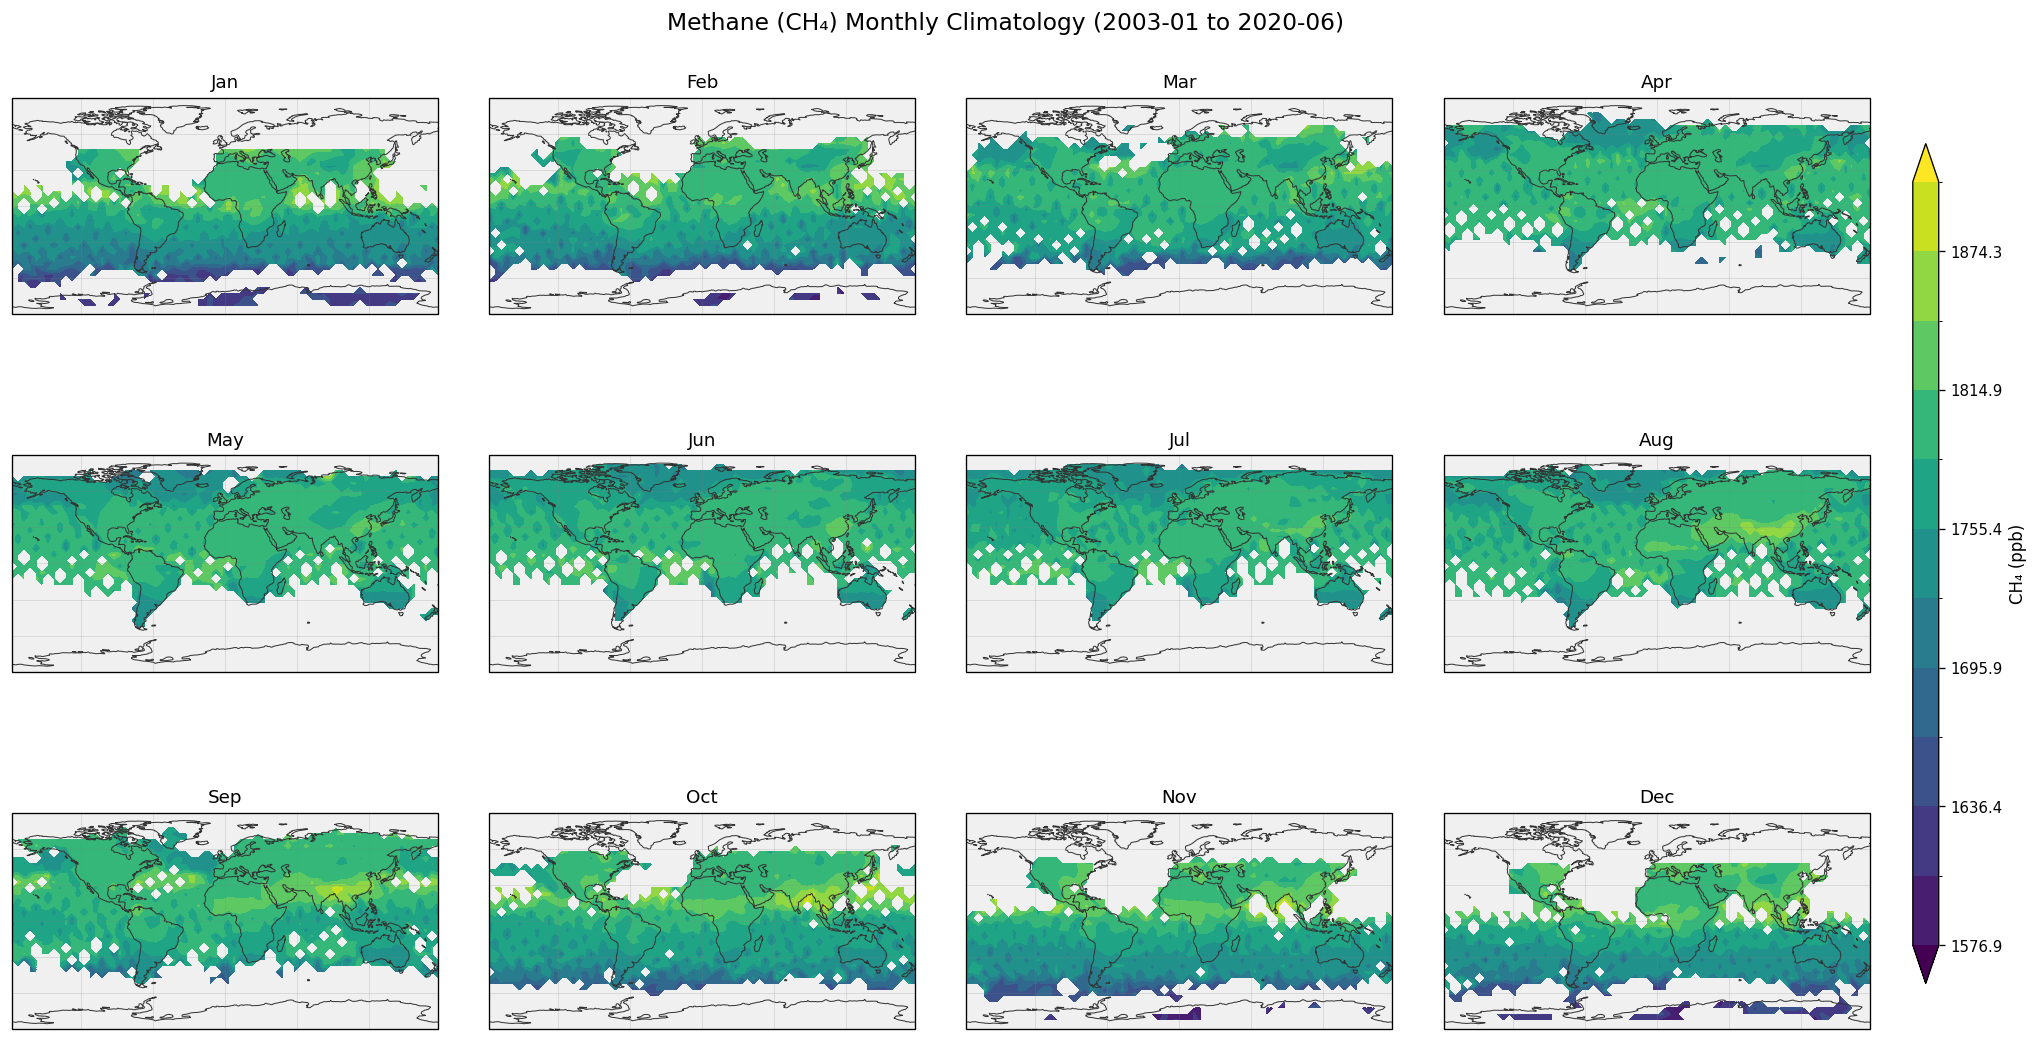

In [3]:
# 2.数据预处理
xch4_clean = xch4_raw.where(xch4_raw < 1e-5)
xch4_ppb = xch4_clean * 1e9
xch4_ppb.attrs["units"] = "ppb"
xch4_clim = xch4_ppb.groupby("time.month").mean(dim="time")

# 3.绘图参数配置
cmap = plt.get_cmap("viridis").with_extremes(bad="#f0f0f0")

vmin = float(xch4_clim.min(skipna=True))
vmax = float(xch4_clim.max(skipna=True))

month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# 4.绘制3行4列子图
fig, axes = plt.subplots(3, 4, figsize=(18, 10), dpi=120,
                         subplot_kw={"projection": ccrs.PlateCarree()})
axes = axes.flatten()

for i in range(12):
    ax = axes[i]
    month_data = xch4_clim.sel(month=i+1)
    
    ax.set_facecolor("#f0f0f0")

    im = month_data.plot.contourf(
        ax=ax,
        transform=ccrs.PlateCarree(),
        levels=12,
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False,
        cmap=cmap,
        extend="both"
    )
    
    ax.coastlines(linewidth=0.6, color="#333333")
    
    ax.gridlines(crs=ccrs.PlateCarree(), linewidth=0.3, color="gray", alpha=0.4)
    
    ax.set_title(month_labels[i], fontsize=11, fontweight="medium")

# 5.精细化布局
cbar_ax = fig.add_axes([0.92, 0.15, 0.012, 0.7])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("CH₄ (ppb)", fontsize=10)
cbar.ax.tick_params(labelsize=9)

plt.subplots_adjust(left=0.04, right=0.9, top=0.92, bottom=0.08, wspace=0.12, hspace=0.22)

plt.suptitle("Methane (CH₄) Monthly Climatology (2003-01 to 2020-06)",
             fontsize=14, y=0.96, fontweight="medium")

plt.show()

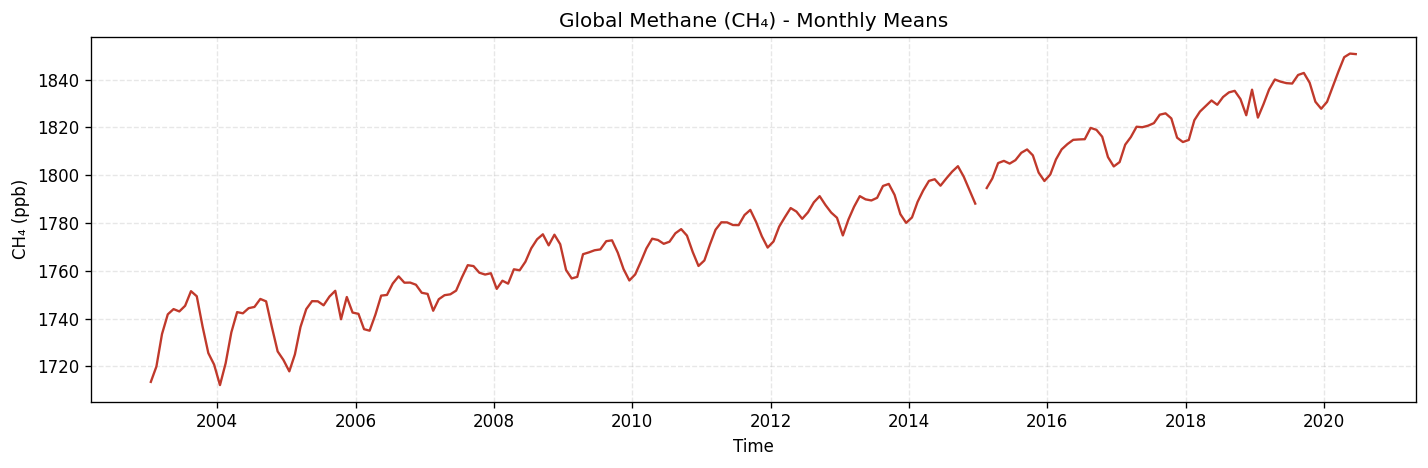

In [4]:
# 1.2
# 1.读取数据
ds = xr.open_dataset("./Data/200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")
xch4 = ds["xch4"]

# 2.数据清洗
xch4_clean = xch4.where(xch4 < 1e-5)
xch4_ppb = xch4_clean * 1e9

# 3.纬度加权计算全球平均
lat_weights = np.cos(np.deg2rad(ds.lat))
xch4_global = xch4_ppb.weighted(lat_weights).mean(dim=["lat", "lon"])

# 4.绘制时间序列
plt.figure(figsize=(12, 4), dpi=120)
xch4_global.plot(color="#c0392b", linewidth=1.4)
plt.title("Global Methane (CH₄) - Monthly Means")
plt.ylabel("CH₄ (ppb)")
plt.xlabel("Time")
plt.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

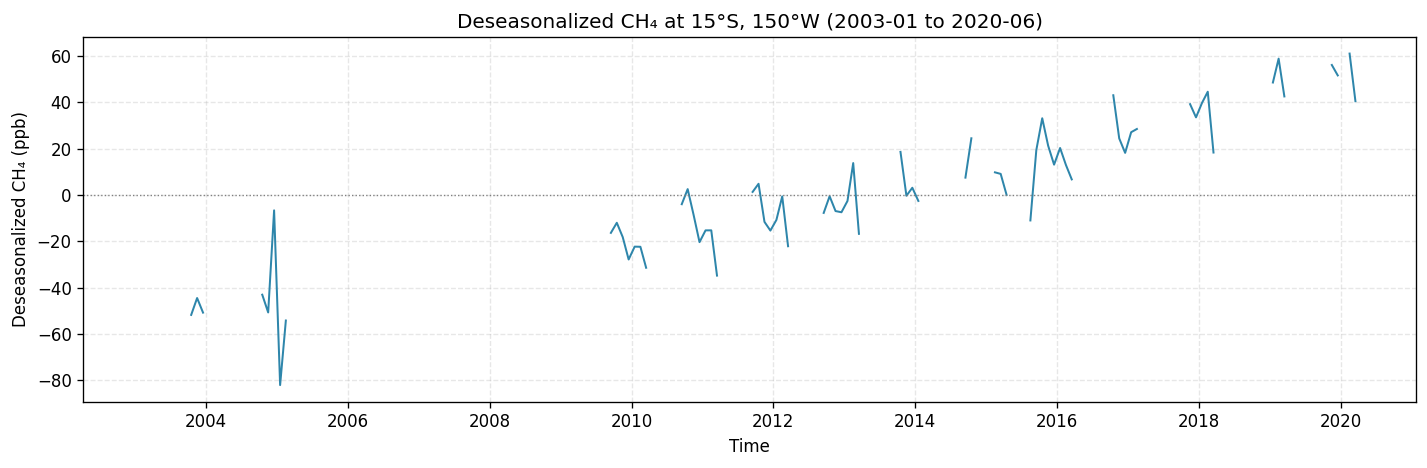

In [5]:
# 1.读取数据
ds = xr.open_dataset("./Data/200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")
xch4_raw = ds["xch4"]

# 2.数据清洗
xch4_clean = xch4_raw.where(xch4_raw < 1e-5)
xch4_ppb = xch4_clean * 1e9

# 3.提取目标点位
point_xch4 = xch4_ppb.sel(lat=-15, lon=-150, method="nearest")

# 4.去季节化
month_clim = point_xch4.groupby("time.month").mean(dim="time")
xch4_deseason = point_xch4.groupby("time.month") - month_clim

# 5.绘图
plt.figure(figsize=(12, 4), dpi=120)
xch4_deseason.plot(color="#2E86AB", linewidth=1.2)
plt.title("Deseasonalized CH₄ at 15°S, 150°W (2003-01 to 2020-06)")
plt.ylabel("Deseasonalized CH₄ (ppb)")
plt.xlabel("Time")
plt.grid(alpha=0.3, linestyle="--")
plt.axhline(y=0, color="gray", linewidth=0.8, linestyle=":")
plt.tight_layout()
plt.show()

# 2. Niño 3.4 index

In [6]:
# 2.1
# 1.读取数据
ds = xr.open_dataset("./Data/NOAA_NCDC_ERSST_v3b_SST.nc")
sst = ds["sst"]

# 2.截取Niño3.4区域
sst = sst.sortby("lat")
nino34_sst = sst.sel(
    lat=slice(-5, 5),
    lon=slice(190, 240)
)

# 3.纬度加权区域平均
lat_weights = np.cos(np.deg2rad(nino34_sst.lat))
nino34_mean = nino34_sst.weighted(lat_weights).mean(dim=["lat", "lon"], skipna=True)

# 4.计算月气候态与SST异常
month_clim = nino34_mean.groupby("time.month").mean(dim="time")
nino34_anom = nino34_mean.groupby("time.month") - month_clim

# 5.查看结果
print("==== 月气候态（1-12月） ====")
print(month_clim)
print("\n==== SST距平序列 ====")
print(nino34_anom)

==== 月气候态（1-12月） ====
<xarray.DataArray 'sst' (month: 12)> Size: 48B
array([26.567791, 26.742275, 27.239607, 27.693745, 27.795218, 27.59776 ,
       27.198921, 26.824205, 26.737831, 26.717144, 26.693287, 26.613096],
      dtype=float32)
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12

==== SST距平序列 ====
<xarray.DataArray 'sst' (time: 684)> Size: 3kB
array([-3.19669724e-01, -4.68566895e-01, -2.68173218e-01, -1.87025070e-01,
       -1.77635193e-01, -3.57749939e-01, -1.42024994e-01,  1.46179199e-02,
       -1.52326584e-01, -3.79959106e-01, -3.60944748e-01, -2.08707809e-01,
       -1.91467285e-01, -1.34252548e-01, -2.40343094e-01, -1.85152054e-01,
        5.19733429e-02,  2.39467621e-01, -7.02838898e-02, -4.18710709e-01,
       -7.78390884e-01, -7.92449951e-01, -4.96278763e-01, -4.17322159e-01,
       -4.44833755e-01, -4.56037521e-01, -4.36143875e-01, -4.66995239e-01,
       -5.64611435e-01, -4.26931381e-01, -2.76756287e-01, -3.17255020e-01,
       -6.73257828e-01, -6

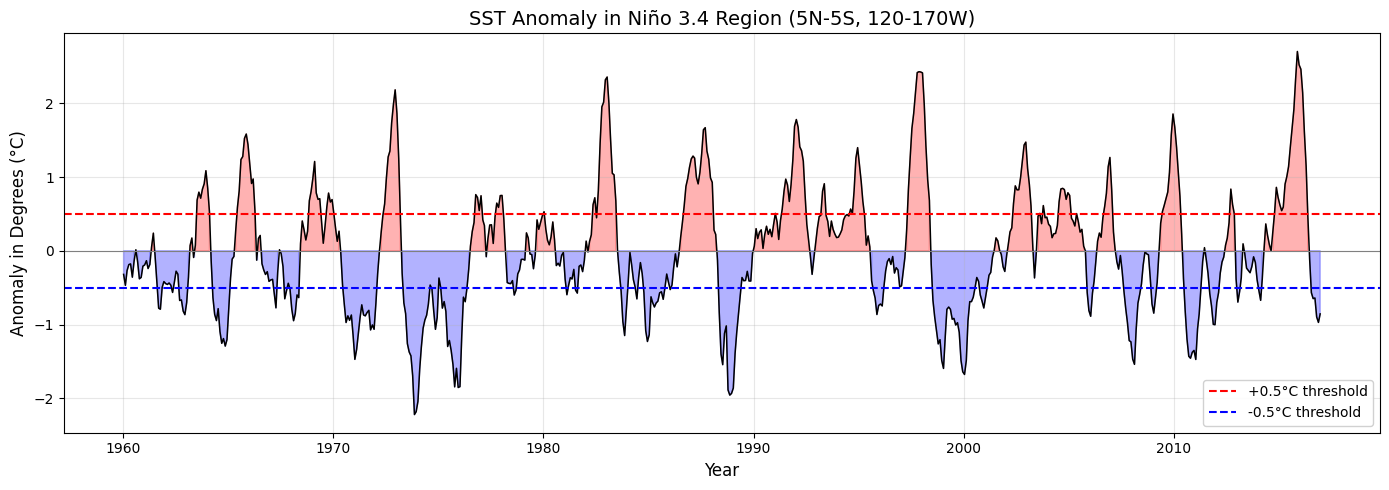

In [7]:
# 2.2
plt.figure(figsize=(14, 5))
nino34_anom.plot(color="black", linewidth=1.1)

plt.fill_between(nino34_anom.time, nino34_anom, 0,
                 where=nino34_anom > 0, color="red", alpha=0.3)
plt.fill_between(nino34_anom.time, nino34_anom, 0,
                 where=nino34_anom < 0, color="blue", alpha=0.3)

plt.axhline(y=0.5, color="red", linestyle="--", label="+0.5°C threshold")
plt.axhline(y=-0.5, color="blue", linestyle="--", label="-0.5°C threshold")
plt.axhline(y=0, color="gray", linewidth=0.8)

plt.title("SST Anomaly in Niño 3.4 Region (5N-5S, 120-170W)", fontsize=14)
plt.ylabel("Anomaly in Degrees (°C)", fontsize=12)
plt.xlabel("Year", fontsize=12)
plt.grid(alpha=0.3)
plt.legend(loc="lower right", framealpha=0.9)
plt.tight_layout()
plt.show()

## 3. Explore a netCDF dataset

In [8]:
# 批量合并所有 nc 文件
ds = xr.open_mfdataset("./Data/FLDAS_NOAH01_CP_GL_M_001/*.nc")

ds["Tair_C"] = ds["Tair_f_tavg"] - 273.15

print(ds)

<xarray.Dataset> Size: 38GB
Dimensions:                 (time: 60, bnds: 2, Y: 1500, X: 3600)
Coordinates:
  * time                    (time) datetime64[ns] 480B 2019-01-01 ... 2023-12-01
  * X                       (X) float64 29kB -179.9 -179.8 ... 179.9 180.0
  * Y                       (Y) float64 12kB -59.95 -59.85 ... 89.85 89.95
Dimensions without coordinates: bnds
Data variables: (12/30)
    time_bnds               (time, bnds) datetime64[ns] 960B dask.array<chunksize=(1, 2), meta=np.ndarray>
    Evap_tavg               (time, Y, X) float32 1GB dask.array<chunksize=(1, 1, 3600), meta=np.ndarray>
    LWdown_f_tavg           (time, Y, X) float32 1GB dask.array<chunksize=(1, 1, 3600), meta=np.ndarray>
    Lwnet_tavg              (time, Y, X) float32 1GB dask.array<chunksize=(1, 1, 3600), meta=np.ndarray>
    Psurf_f_tavg            (time, Y, X) float32 1GB dask.array<chunksize=(1, 1, 3600), meta=np.ndarray>
    Qair_f_tavg             (time, Y, X) float32 1GB dask.array<chunksize=

In [9]:
# 重命名维度为标准经纬度名称
ds = ds.rename({"X": "lon", "Y": "lat"})
# 验证重命名结果
print("当前维度：", ds.dims)

当前维度： FrozenMappingWarningOnValuesAccess({'time': 60, 'bnds': 2, 'lat': 1500, 'lon': 3600})


In [10]:
# 裁剪东亚区域
# 经度范围：70°E~140°E，纬度范围：15°N~55°N
ds_region = ds.sel(lon=slice(70, 140), lat=slice(15, 55))

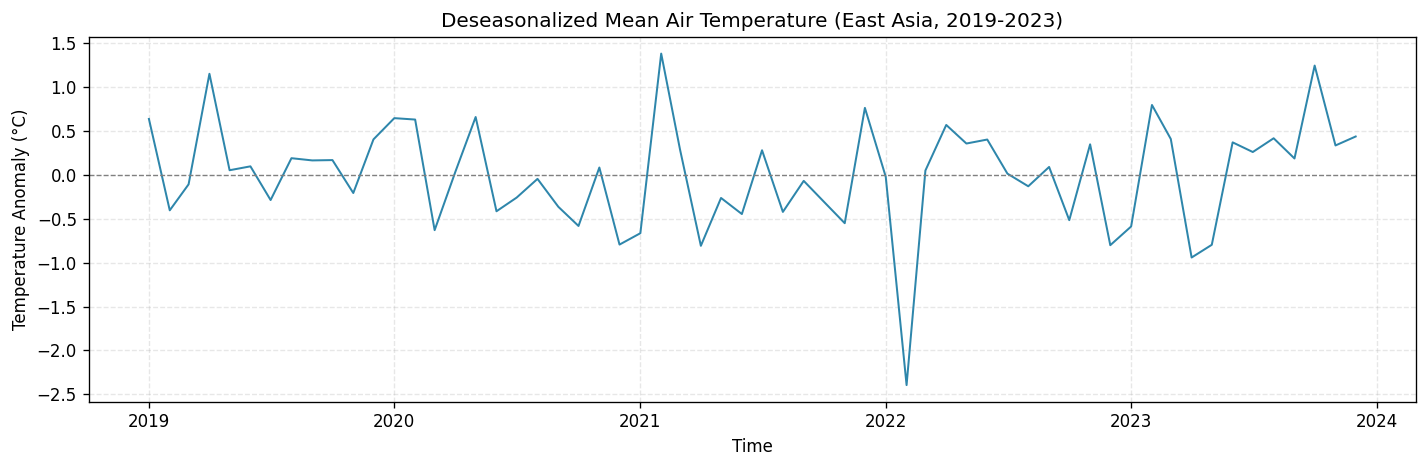

In [11]:
# 1.1
# 1.区域加权平均 + 去季节化
lat_weights = np.cos(np.deg2rad(ds_region.lat))
tair_region = ds_region["Tair_C"].weighted(lat_weights).mean(dim=["lat", "lon"])

# 2.计算月气候态，去除季节循环
tair_clim = tair_region.groupby("time.month").mean("time")
tair_deseason = tair_region.groupby("time.month") - tair_clim

# 3.绘图
plt.figure(figsize=(12, 4), dpi=120)
tair_deseason.plot(color="#2E86AB", linewidth=1.2)
plt.axhline(y=0, color="gray", linestyle="--", linewidth=0.8)
plt.title("Deseasonalized Mean Air Temperature (East Asia, 2019-2023)")
plt.ylabel("Temperature Anomaly (°C)")
plt.xlabel("Time")
plt.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

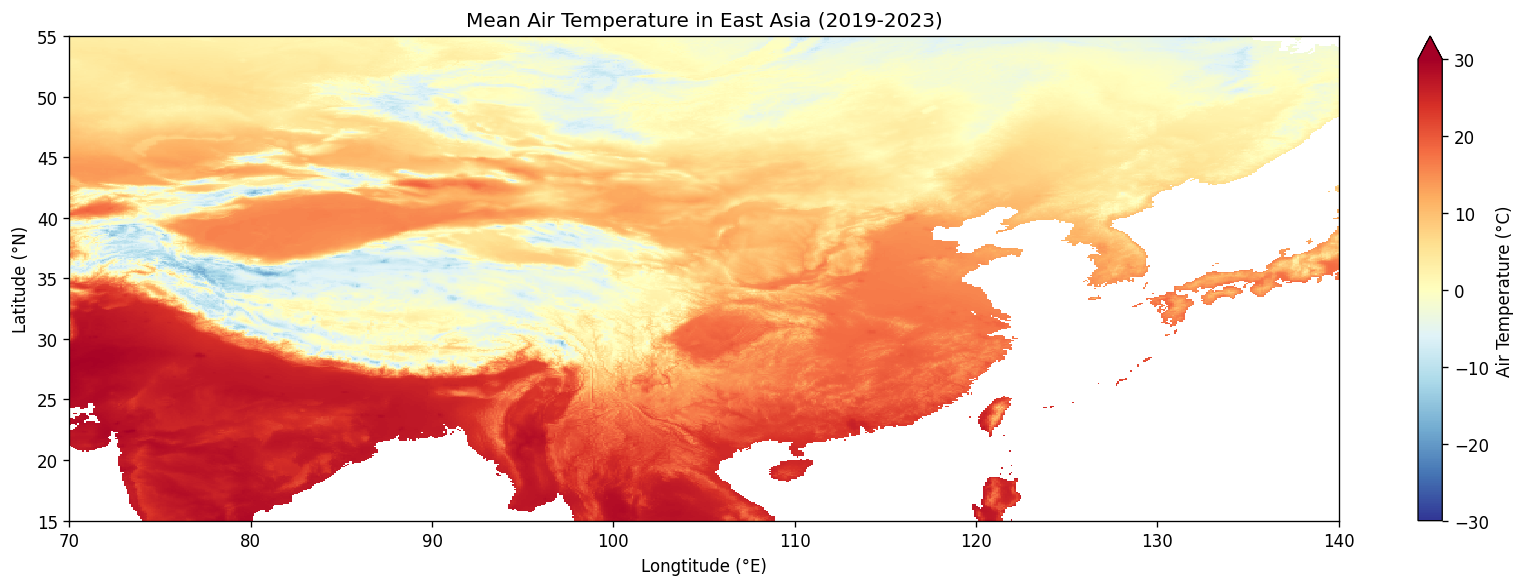

In [12]:
#图 1：年平均气温空间分布图
tair_mean = ds_region["Tair_C"].mean("time")

plt.figure(figsize=(14, 5), dpi=120)
tair_mean.plot(cmap="RdYlBu_r", vmin=-30, vmax=30, cbar_kwargs={"label": "Air Temperature (°C)"})
plt.title("Mean Air Temperature in East Asia (2019-2023)")
plt.ylabel("Latitude (°N)")
plt.xlabel("Longtitude (°E)")
plt.tight_layout()
plt.show()

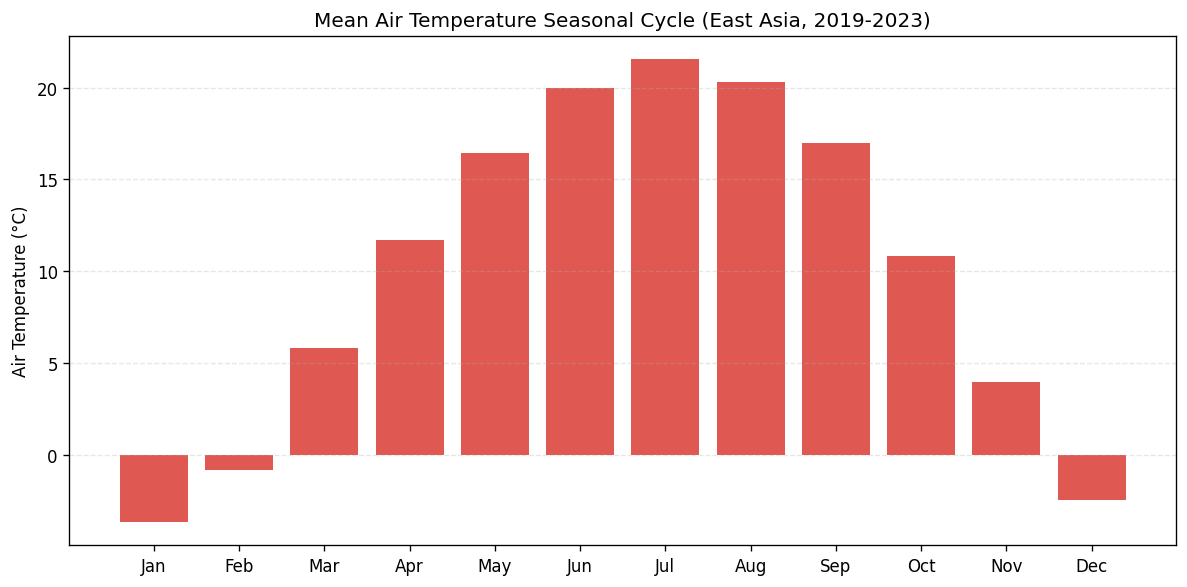

In [13]:
#图 2：平均气温季节循环柱状图
# 1.做空间加权平均，得到一维时间序列
lat_weights = np.cos(np.deg2rad(ds_region.lat))
tair_region = ds_region["Tair_C"].weighted(lat_weights).mean(dim=["lat", "lon"])

# 2.计算月气候态
tair_clim = tair_region.groupby("time.month").mean("time")

# 3.绘图
plt.figure(figsize=(10, 5), dpi=120)
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
plt.bar(months, tair_clim.values, color="#d73027", alpha=0.8)

plt.title("Mean Air Temperature Seasonal Cycle (East Asia, 2019-2023)")
plt.ylabel("Air Temperature (°C)")
plt.grid(axis="y", alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()

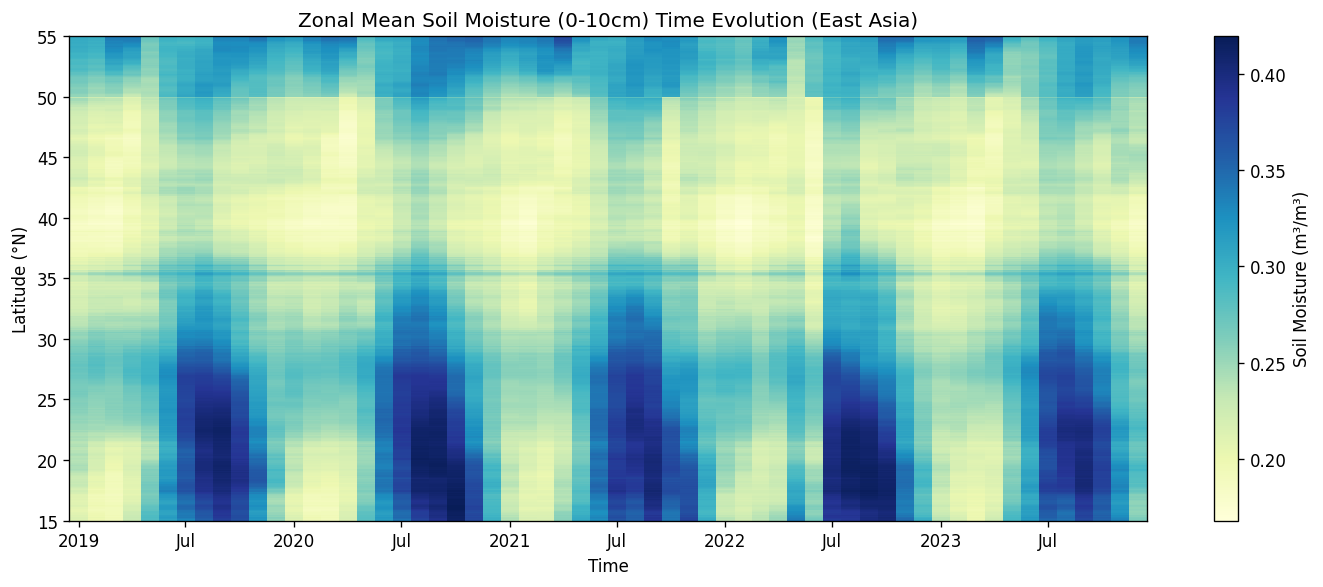

In [14]:
#图 3：土壤湿度纬向平均时间演变图
sm_zonal = ds_region["SoilMoi00_10cm_tavg"].mean("lon")

plt.figure(figsize=(12, 5), dpi=120)

sm_zonal.T.plot(cmap="YlGnBu", cbar_kwargs={"label": "Soil Moisture (m³/m³)"})
plt.title("Zonal Mean Soil Moisture (0-10cm) Time Evolution (East Asia)")
plt.ylabel("Latitude (°N)")
plt.xlabel("Time")
plt.tight_layout()
plt.show()

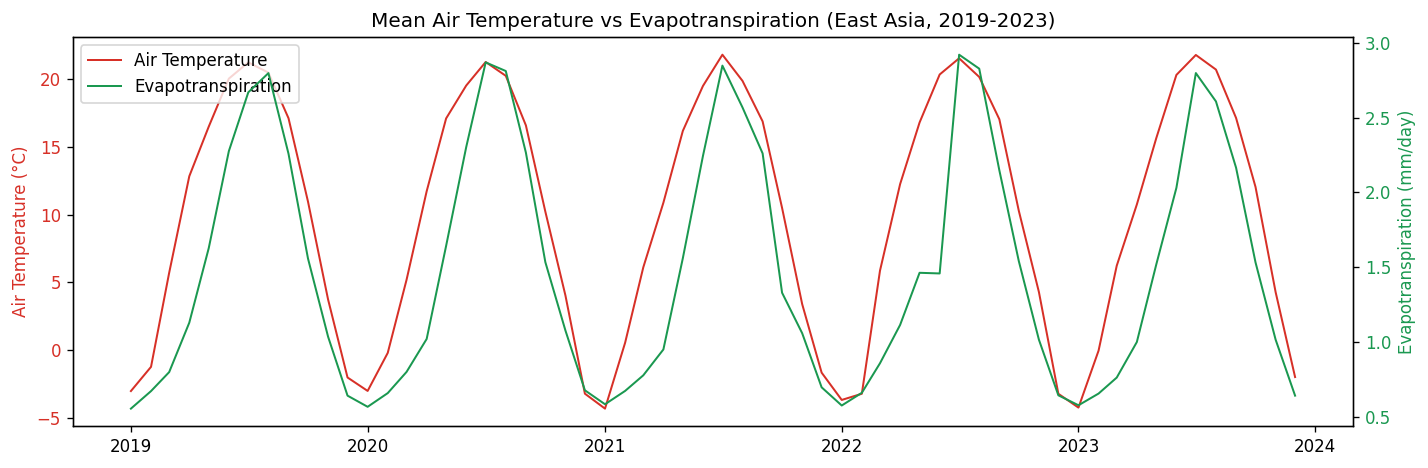

In [15]:
#图 4：气温与蒸散双轴对比序列图
# 1.蒸散单位转换
ds_region["Evap_mmday"] = ds_region["Evap_tavg"] * 86400

# 2.计算区域加权平均序列
tair_region = ds_region["Tair_C"].weighted(lat_weights).mean(dim=["lat", "lon"])
evap_region = ds_region["Evap_mmday"].weighted(lat_weights).mean(dim=["lat", "lon"])

fig, ax1 = plt.subplots(figsize=(12, 4), dpi=120)

# 左轴：气温
color1 = "#d73027"
line1, = ax1.plot(ds_region.time, tair_region, color=color1, linewidth=1.2, label="Air Temperature")
ax1.set_ylabel("Air Temperature (°C)", color=color1)
ax1.tick_params(axis="y", labelcolor=color1)

# 右轴：蒸散
ax2 = ax1.twinx()
color2 = "#1a9850"
line2, = ax2.plot(ds_region.time, evap_region, color=color2, linewidth=1.2, label="Evapotranspiration")
ax2.set_ylabel("Evapotranspiration (mm/day)", color=color2)
ax2.tick_params(axis="y", labelcolor=color2)

ax1.legend(handles=[line1, line2], loc="upper left")

plt.title("Mean Air Temperature vs Evapotranspiration (East Asia, 2019-2023)")
fig.tight_layout()
plt.show()

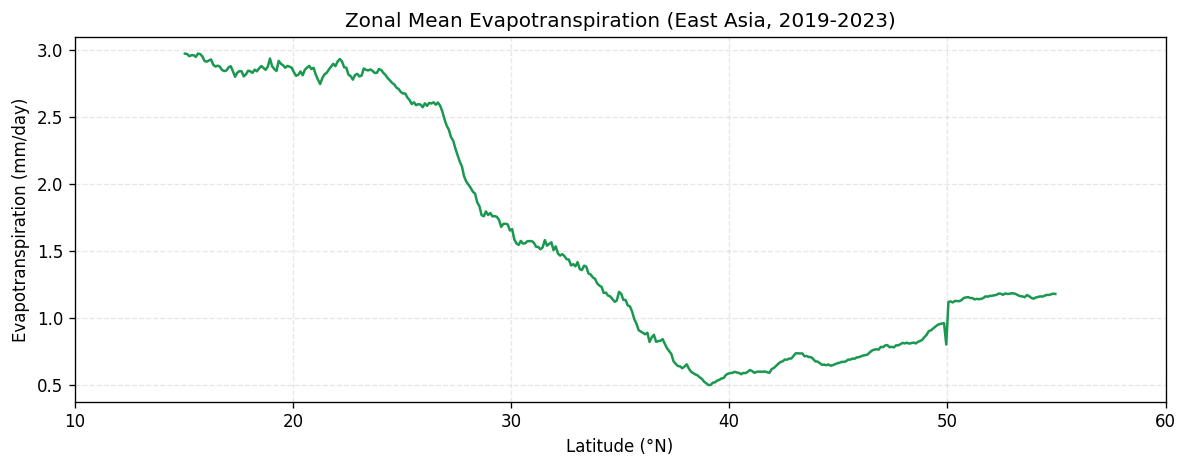

In [16]:
#图 5：多年平均蒸散纬向分布曲线
evap_zonal_mean = ds_region["Evap_mmday"].mean("time").mean("lon")

plt.figure(figsize=(10, 4), dpi=120)
plt.plot(evap_zonal_mean.lat, evap_zonal_mean.values, color="#1a9850", linewidth=1.5)
plt.axvline(x=0, color="gray", linestyle="--", linewidth=0.8)
plt.title("Zonal Mean Evapotranspiration (East Asia, 2019-2023)")
plt.xlabel("Latitude (°N)")
plt.ylabel("Evapotranspiration (mm/day)")
plt.xlim(10, 60)
plt.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.show()